<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS09/lab5_js09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 – Instal Library
Pasang FAISS versi CPU, ANNOY, dan hnswlib. Instalasi cukup dilakukan sekali pada sesi runtime.

In [1]:
!pip install -q faiss-cpu annoy hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Langkah 2 – Import Library
Import library yang dibutuhkan untuk membuat dataset, membangun indeks, mengukur waktu, dan menggambar grafik.

In [2]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

print('Semua library berhasil diimpor.')

Semua library berhasil diimpor.


## Langkah 3 – Membuat Dataset Random
Buat database vector sebanyak 100.000 dengan 128 dimensi dan 1.000 query vector. Seed 42 digunakan agar dataset dapat direproduksi.

In [3]:
# Dataset random
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

print('Database shape:', xb.shape)
print('Query shape:', xq.shape)
print('Database size (MiB):', round(xb.nbytes / (1024 ** 2), 2))

Database shape: (100000, 128)
Query shape: (1000, 128)
Database size (MiB): 48.83


## Langkah 4 – Membuat Ground Truth dengan FAISS Brute Force
Ground truth adalah 10 tetangga terdekat yang benar untuk setiap query. FAISS `IndexFlatL2` melakukan pencarian exact pada seluruh database. Indeks tetangga (`gt_idx`) ini akan menjadi pembanding untuk ketiga metode ANN.

In [4]:
# Ground truth dengan FAISS brute force
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

print('Ground truth shape:', gt_idx.shape)
print('10 tetangga pertama untuk query pertama:', gt_idx[0])

Ground truth shape: (1000, 10)
10 tetangga pertama untuk query pertama: [19523 72727 34414 30313 31191  3890  7176 86931  4934 20772]


## Langkah 5 – Membuat Fungsi Recall@K
Recall@K menghitung jumlah tetangga yang sama antara hasil prediksi ANN dan ground truth, dibagi total tetangga acuan (`jumlah query × k`). Recall bernilai 1 berarti semua tetangga yang ditemukan sama dengan ground truth pada top-K.

In [5]:
# Fungsi recall
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

print('Contoh Recall@10 jika hasil dibandingkan dengan dirinya sendiri:',
      recall_at_k(gt_idx, gt_idx, k))

Contoh Recall@10 jika hasil dibandingkan dengan dirinya sendiri: 1.0


## Langkah 6 – Benchmark ANNOY
Fungsi berikut membangun indeks ANNOY dengan 10 trees, kemudian melakukan pencarian untuk seluruh query. Parameter `search_k` diuji pada empat nilai. Waktu dihitung sebagai rata-rata milidetik per query. Waktu pembangunan indeks tidak termasuk dalam query time.

In [6]:
# Benchmark Annoy
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.perf_counter()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

print('Fungsi benchmark ANNOY siap digunakan.')

Fungsi benchmark ANNOY siap digunakan.


## Langkah 7 – Benchmark FAISS IVF
FAISS IVF membagi database ke dalam inverted lists. Parameter `nlist=100` menentukan jumlah cluster, sedangkan `nprobe` menentukan berapa cluster yang diperiksa ketika pencarian. Semakin besar `nprobe`, pencarian cenderung lebih menyeluruh sehingga recall dapat meningkat, tetapi query time juga dapat bertambah.

In [7]:
# Benchmark FAISS IVF
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.perf_counter()
    _, I = index.search(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

print('Fungsi benchmark FAISS IVF siap digunakan.')

Fungsi benchmark FAISS IVF siap digunakan.


## Langkah 8 – Benchmark HNSW
HNSW menggunakan struktur graph untuk menemukan tetangga terdekat. Parameter `M=16` dan `ef_construction=200` digunakan saat membangun indeks, sedangkan `ef` mengatur cakupan pencarian. Nilai `ef` yang lebih besar biasanya meningkatkan recall dengan konsekuensi query time yang lebih tinggi.

In [8]:
# Benchmark HNSW
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.perf_counter()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

print('Fungsi benchmark HNSW siap digunakan.')

Fungsi benchmark HNSW siap digunakan.


## Langkah 9 – Menjalankan Benchmark dengan Beberapa Parameter
Setiap algoritma diuji menggunakan empat konfigurasi parameter. Fungsi benchmark membangun indeks dan mengukur query time; yang dilaporkan sebagai performa adalah recall dan rata-rata waktu per query. Proses ini dapat memerlukan waktu beberapa menit.

In [9]:
# Jalankan benchmark dengan beberapa parameter
results = {'Annoy': [], 'Faiss': [], 'HNSW': []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk, k=k)
    results['Annoy'].append((rec, t))
    print(f'Annoy search_k={sk}: Recall={rec:.4f}, Query={t:.4f} ms/query')

# FAISS IVF
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb, k=k)
    results['Faiss'].append((rec, t))
    print(f'FAISS nprobe={npb}: Recall={rec:.4f}, Query={t:.4f} ms/query')

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef, M=16, k=k)
    results['HNSW'].append((rec, t))
    print(f'HNSW ef={ef}: Recall={rec:.4f}, Query={t:.4f} ms/query')

Annoy search_k=200: Recall=0.0202, Query=0.0759 ms/query
Annoy search_k=500: Recall=0.0429, Query=0.0962 ms/query
Annoy search_k=1000: Recall=0.0764, Query=0.1624 ms/query
Annoy search_k=2000: Recall=0.1284, Query=0.2881 ms/query
FAISS nprobe=1: Recall=0.0554, Query=0.0255 ms/query
FAISS nprobe=5: Recall=0.1912, Query=0.0868 ms/query
FAISS nprobe=10: Recall=0.3182, Query=0.1776 ms/query
FAISS nprobe=20: Recall=0.5009, Query=0.3782 ms/query
HNSW ef=50: Recall=0.2997, Query=0.1241 ms/query
HNSW ef=100: Recall=0.4415, Query=0.2196 ms/query
HNSW ef=200: Recall=0.6080, Query=0.4038 ms/query
HNSW ef=400: Recall=0.7709, Query=0.8119 ms/query


## Langkah 10 – Visualisasi Trade-off Recall dan Query Time
Sumbu X menunjukkan Recall@10. Sumbu Y menunjukkan query time (ms/query) dengan skala logaritmik dan dibalik agar waktu yang lebih cepat berada lebih tinggi pada grafik. Dengan demikian, area kanan atas menggambarkan kombinasi recall tinggi dan query time rendah.

**Catatan modul:** Uraian konsep modul menyebut QPS (queries per second), tetapi kode dan grafik praktikumnya menggunakan query time (ms/query). Notebook ini mengikuti kode praktikum: sumbu Y adalah query time, bukan QPS.

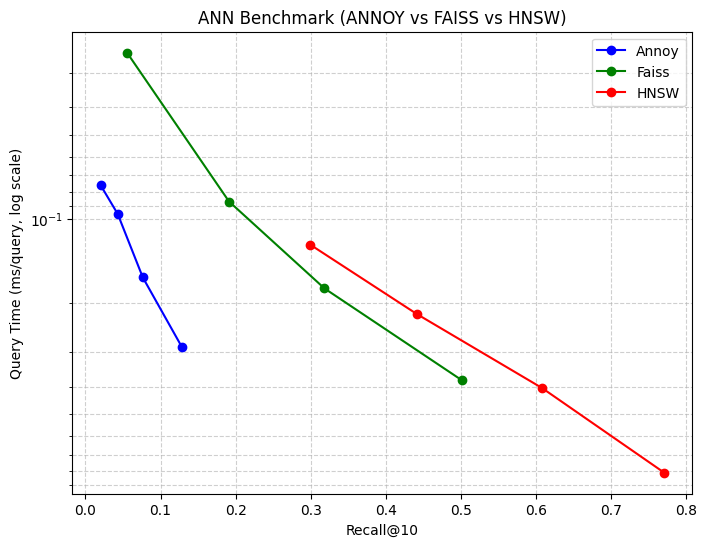

In [10]:
# Visualisasi trade-off
plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ['blue', 'green', 'red']):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker='o', label=label, color=color)

plt.xlabel('Recall@10')
plt.ylabel('Query Time (ms/query, log scale)')
plt.yscale('log')
plt.gca().invert_yaxis()  # query time lebih kecil ditampilkan lebih tinggi
plt.title('ANN Benchmark (ANNOY vs FAISS vs HNSW)')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.show()

## Langkah 11 – Tabel Ringkasan Hasil
Tabel berikut memudahkan pembacaan nilai Recall@10 dan query time setiap konfigurasi. Gunakan tabel ini bersama grafik untuk menentukan konfigurasi yang paling sesuai.

In [11]:
import pandas as pd

rows = []
parameter_values = {
    'Annoy': [200, 500, 1000, 2000],
    'Faiss': [1, 5, 10, 20],
    'HNSW': [50, 100, 200, 400]
}
parameter_names = {'Annoy': 'search_k', 'Faiss': 'nprobe', 'HNSW': 'ef'}

for method, values in results.items():
    for param, (rec, qtime) in zip(parameter_values[method], values):
        rows.append({
            'Metode': method,
            parameter_names[method]: param,
            'Recall@10': rec,
            'Query time (ms/query)': qtime
        })

summary = pd.DataFrame(rows)
display(summary)

,Metode,search_k,Recall@10,Query time (ms/query),nprobe,ef
0,Annoy,200.0,0.0202,0.075945,NaN,NaN
1,Annoy,500.0,0.0429,0.096179,NaN,NaN
2,Annoy,1000.0,0.0764,0.162417,NaN,NaN
3,Annoy,2000.0,0.1284,0.288081,NaN,NaN
4,Faiss,NaN,0.0554,0.025472,1.0,NaN
5,Faiss,NaN,0.1912,0.086829,5.0,NaN
6,Faiss,NaN,0.3182,0.177625,10.0,NaN
7,Faiss,NaN,0.5009,0.378223,20.0,NaN
8,HNSW,NaN,0.2997,0.124102,NaN,50.0
9,HNSW,NaN,0.4415,0.219644,NaN,100.0


## Analisis dan Kesimpulan
Evaluasi ANN tidak cukup hanya mengukur kecepatan. Kualitas hasil pencarian perlu dinilai dengan Recall@K dan dibandingkan dengan ground truth. Pemilihan algoritma dan parameter terbaik bergantung pada kebutuhan akurasi serta batas waktu pencarian.

### Catatan interpretasi
- Recall@10 = 1 berarti seluruh 10 tetangga hasil ANN cocok dengan 10 tetangga ground truth untuk seluruh query secara agregat.
- Query time lebih kecil berarti pencarian lebih cepat.
- Karena sumbu Y dibalik, titik lebih tinggi menunjukkan query time lebih rendah.
- Hasil dapat berbeda karena versi library, perangkat, dan kondisi runtime.
- Notebook mengikuti alur modul yang membangun ulang indeks pada setiap konfigurasi; waktu pembangunan tidak dimasukkan ke dalam query time.